# DFG, OPA e four-wave mixing

### Subject: Nonlinear optics

Il notebook `01` copre SHG e $n_2$. Qui l'inverso: **difference-frequency
generation** / **optical parametric amplifier**. Un fotone di pompa $\omega_p$
si spezza in segnale $\omega_s$ e idler $\omega_i$,

$$
\omega_p=\omega_s+\omega_i,
$$

e l'ampiezza del segnale può *crescere* (guadagno parametrico), non
solo convertirsi. In coda: Manley–Rowe e lo schema $\chi^{(3)}$ di
four-wave mixing.

Slide del modulo: `data/` (gitignored).


## 0. Setup


In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.figsize": (8, 4.4),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 11,
})

def rk4(f, y0, t):
    y = np.empty((len(t),) + np.shape(y0), dtype=np.asarray(y0).dtype)
    y[0] = y0
    for i in range(len(t) - 1):
        h = t[i + 1] - t[i]
        k1 = f(t[i], y[i])
        k2 = f(t[i] + 0.5 * h, y[i] + 0.5 * h * k1)
        k3 = f(t[i] + 0.5 * h, y[i] + 0.5 * h * k2)
        k4 = f(t[i] + h, y[i] + h * k3)
        y[i + 1] = y[i] + (h / 6.0) * (k1 + 2 * k2 + 2 * k3 + k4)
    return y

print("Setup ready.")


Setup ready.


## 1. Pompa indepleta, phase matching

Con pompa classica fissa e $\Delta k=k_p-k_s-k_i$,

$$
\frac{dA_s}{dz}=i\Gamma A_i^* e^{i\Delta k z},\qquad
\frac{dA_i}{dz}=i\Gamma A_s^* e^{i\Delta k z}.
$$

Se $\Delta k=0$ e $A_i(0)=0$:

$$
A_s(z)=A_s(0)\cosh(\Gamma z),\qquad
A_i(z)=i A_s(0)\sinh(\Gamma z).
$$

Il segnale non oscilla: **esplode** (finché la pompa non si esaurisce).
È l'opposto della SHG a bassa conversione.


RK4 vs cosh/sinh:  ΔAs=2.79e-11  ΔAi=2.84e-11
Manley–Rowe drift = 3.20e-14


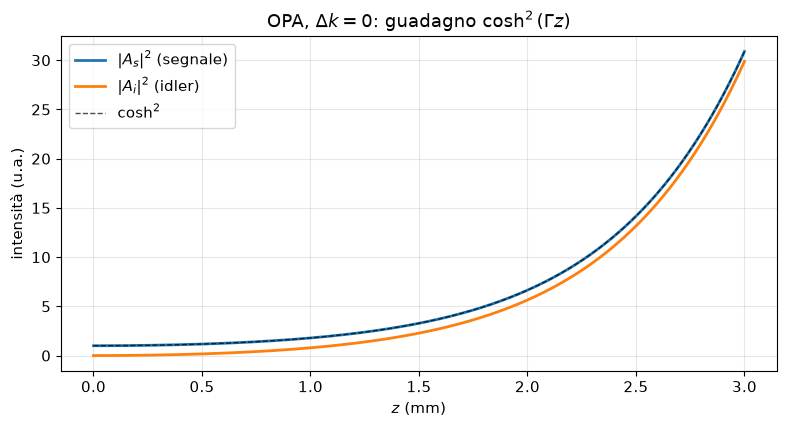

In [2]:
Gamma = 0.8  # 1/mm
L = 3.0      # mm
z = np.linspace(0.0, L, 601)
As0 = 1.0 + 0j


def opa_analytic(z, G):
    As = As0 * np.cosh(G * z)
    Ai = 1j * As0 * np.sinh(G * z)
    return As, Ai


def opa_rhs(dk):
    def f(zi, u):
        As = u[0] + 1j * u[1]
        Ai = u[2] + 1j * u[3]
        phase = np.exp(1j * dk * zi)
        dAs = 1j * Gamma * np.conj(Ai) * phase
        dAi = 1j * Gamma * np.conj(As) * phase
        return np.array([dAs.real, dAs.imag, dAi.real, dAi.imag])
    return f


u0 = np.array([As0.real, As0.imag, 0.0, 0.0])
u_pm = rk4(opa_rhs(0.0), u0, z)
As_num = u_pm[:, 0] + 1j * u_pm[:, 1]
Ai_num = u_pm[:, 2] + 1j * u_pm[:, 3]
As_th, Ai_th = opa_analytic(z, Gamma)

err_s = np.max(np.abs(As_num - As_th))
err_i = np.max(np.abs(Ai_num - Ai_th))
print(f"RK4 vs cosh/sinh:  ΔAs={err_s:.2e}  ΔAi={err_i:.2e}")
assert err_s < 2e-4 and err_i < 2e-4

# Manley–Rowe: |As|² − |Ai|² = |As0|²
mr = np.abs(As_num) ** 2 - np.abs(Ai_num) ** 2
print(f"Manley–Rowe drift = {np.max(np.abs(mr - np.abs(As0)**2)):.2e}")
assert np.max(np.abs(mr - 1.0)) < 2e-4

fig, ax = plt.subplots()
ax.plot(z, np.abs(As_num) ** 2, lw=2, label=r"$|A_s|^2$ (segnale)")
ax.plot(z, np.abs(Ai_num) ** 2, lw=2, label=r"$|A_i|^2$ (idler)")
ax.plot(z, np.abs(As_th) ** 2, "k--", lw=1.0, alpha=0.7, label=r"$\cosh^2$")
ax.set_xlabel("$z$ (mm)")
ax.set_ylabel("intensità (u.a.)")
ax.legend()
ax.set_title(r"OPA, $\Delta k=0$: guadagno $\cosh^2(\Gamma z)$")
plt.tight_layout()
plt.show()


## 2. Mismatch: il guadagno diventa oscillazione

Se $\Delta k\neq 0$ il parametro efficace è
$g=\sqrt{\Gamma^2-(\Delta k/2)^2}$ (o immaginario se $|\Delta k|>2\Gamma$).
Sotto soglia il segnale **non** cresce: si comporta come una SHG
mal accoppiata. Sopra soglia cresce, ma meno che a $\Delta k=0$.


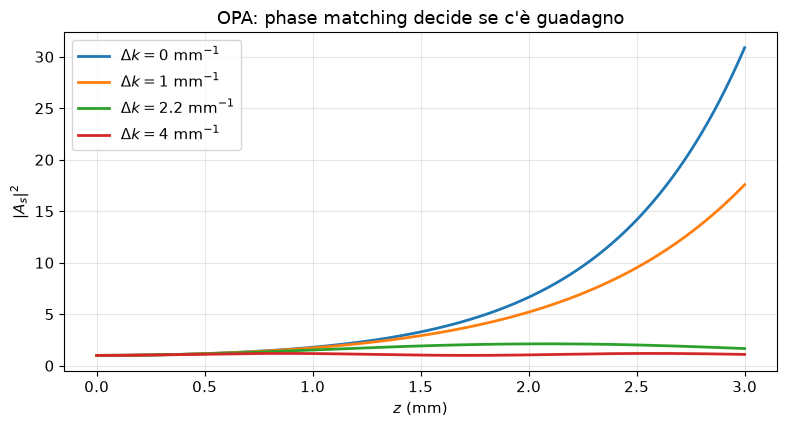

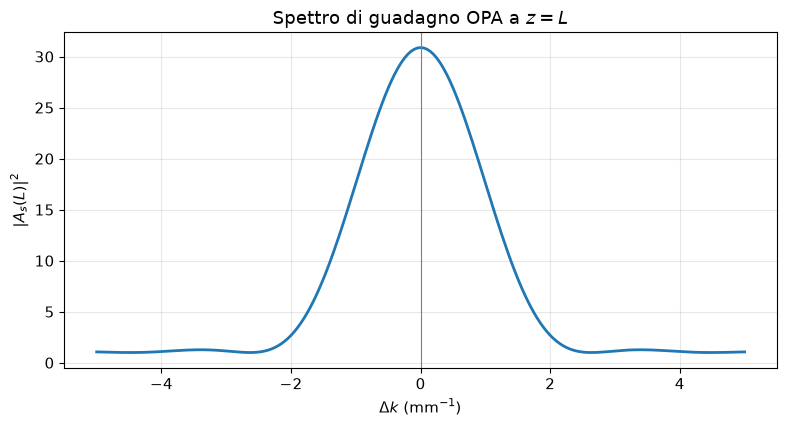

peak gain at Δk=0.000  |As(L)|²=30.880


In [3]:
dks = np.array([0.0, 1.0, 2.2, 4.0])  # 1/mm
fig, ax = plt.subplots()
for dk in dks:
    u = rk4(opa_rhs(dk), u0, z)
    Is = u[:, 0] ** 2 + u[:, 1] ** 2
    ax.plot(z, Is, lw=2, label=rf"$\Delta k={dk:g}$ mm$^{{-1}}$")
ax.set_xlabel("$z$ (mm)")
ax.set_ylabel(r"$|A_s|^2$")
ax.legend()
ax.set_title("OPA: phase matching decide se c'è guadagno")
plt.tight_layout()
plt.show()

# scan of end-facet gain vs Δk
dk_scan = np.linspace(-5.0, 5.0, 201)
gain = []
for dk in dk_scan:
    u = rk4(opa_rhs(dk), u0, z)
    gain.append(u[-1, 0] ** 2 + u[-1, 1] ** 2)
gain = np.array(gain)

fig, ax = plt.subplots()
ax.plot(dk_scan, gain, lw=2)
ax.axvline(0.0, color="0.5", lw=0.8)
ax.set_xlabel(r"$\Delta k$ (mm$^{-1}$)")
ax.set_ylabel(r"$|A_s(L)|^2$")
ax.set_title("Spettro di guadagno OPA a $z=L$")
plt.tight_layout()
plt.show()
print(f"peak gain at Δk={dk_scan[np.argmax(gain)]:.3f}  |As(L)|²={gain.max():.3f}")


## 3. Four-wave mixing, in una riga eseguibile

$\chi^{(3)}$: tre onde ne scrivono una quarta,
$\omega_1+\omega_2=\omega_3+\omega_4$ (energia) e
$\mathbf k_1+\mathbf k_2=\mathbf k_3+\mathbf k_4$ (impulso).
Caso degenerato $2\omega_p=\omega_s+\omega_i$: è un OPA cubico.
Phase conjugation: $k_4=k_1+k_2-k_3$ ribalta il fronte d'onda.

Qui verifichiamo solo la **contabilità dei fotoni** su una griglia di
frequenze: se due pompa a $\omega$ spariscono, nascono $\omega\pm\delta$.


energia 2ω = (ω+δ)+(ω-δ)? True


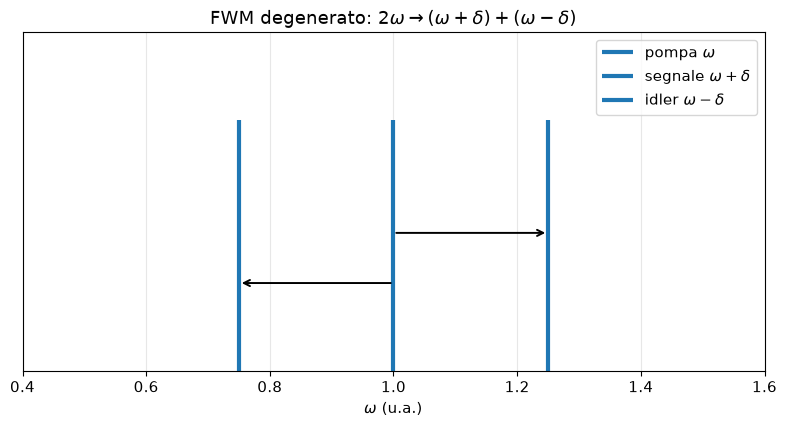

In [4]:
omega = np.linspace(0.4, 1.6, 241)
pump = 1.0
delta = 0.25
lines = [
    (pump, "pompa $\\omega$"),
    (pump + delta, "segnale $\\omega+\\delta$"),
    (pump - delta, "idler $\\omega-\\delta$"),
]
print("energia 2ω = (ω+δ)+(ω-δ)?", np.isclose(2 * pump, (pump + delta) + (pump - delta)))

fig, ax = plt.subplots()
ax.axhline(0.0, color="0.5", lw=0.6)
for w, lab in lines:
    ax.vlines(w, 0.0, 1.0, lw=3, label=lab)
ax.annotate("", xy=(pump + delta, 0.55), xytext=(pump, 0.55),
            arrowprops=dict(arrowstyle="->", lw=1.4))
ax.annotate("", xy=(pump - delta, 0.35), xytext=(pump, 0.35),
            arrowprops=dict(arrowstyle="->", lw=1.4))
ax.set_xlim(0.4, 1.6)
ax.set_ylim(0.0, 1.35)
ax.set_xlabel(r"$\omega$ (u.a.)")
ax.set_yticks([])
ax.legend(loc="upper right")
ax.set_title(r"FWM degenerato: $2\omega\to(\omega+\delta)+(\omega-\delta)$")
plt.tight_layout()
plt.show()


## Takeaway

- SHG: due fotoni $\to$ uno a $2\omega$, efficienza $\mathrm{sinc}^2$.
- OPA/DFG: un fotone di pompa $\to$ segnale + idler, guadagno $\cosh^2$.
- Manley–Rowe: si conservano *differenze* di numeri d'occupazione, non
  il numero totale di fotoni.
- FWM è lo stesso bilancio con tre campi in ingresso.

## Next step
- Pompa depleta: accoppiare anche $A_p$ e vedere il guadagno saturare.
- SVEA + GVM: inviluppi che camminano a $v_g$ diverse.
